# Disaster Tweet Classification — NLP Project
**Author:** Ashish Kumar · Data Scientist, Next Hikes

Goal: classify a tweet as a **real disaster (1)** or **not (0)**.
Pipeline: EDA → cleaning → feature engineering → model selection → evaluation → serialization for Flask.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    classification_report
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. Set your project path
# --------------------------------------------------
ROOT = Path(
    r"D:\nexthikes solutions internship\Project7\disaster_tweet_nlp"
)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}\n"
        "Check the folder path and ensure the drive is accessible."
    )

# --------------------------------------------------
# 2. Locate features.py
# --------------------------------------------------
possible_paths = [
    ROOT / "src" / "features.py",
    ROOT / "features.py"
]

features_file = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if features_file is None:
    raise FileNotFoundError(
        "features.py was not found.\n"
        f"Checked:\n"
        f"  {ROOT / 'src' / 'features.py'}\n"
        f"  {ROOT / 'features.py'}\n\n"
        "Check whether the file exists elsewhere in your project."
    )

# --------------------------------------------------
# 3. Import custom feature functions
# --------------------------------------------------
SRC_DIR = features_file.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from features import TextPrep, MetaFeatures, clean_text, tokenize

# --------------------------------------------------
# 4. Set output directory
# --------------------------------------------------
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 5. Configure reproducibility and plotting
# --------------------------------------------------
SEED = 42
sns.set_theme(style="whitegrid")

print("All imports completed successfully!")
print(f"Project root: {ROOT}")
print(f"Features file: {features_file}")
print(f"Figures directory: {FIG}")
print(f"Random seed: {SEED}")

All imports completed successfully!
Project root: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp
Features file: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\src\features.py
Figures directory: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures
Random seed: 42


## Part 1 — Data exploration & preparation

In [2]:
df = pd.read_excel(os.path.join(ROOT, "data", "twitter_disaster.xlsx"))
print(df.shape); print(df.dtypes); print(df.isna().sum()); df.head()

(7613, 5)
id           int64
keyword     object
location    object
text        object
target       int64
dtype: object
id             0
keyword       61
location    2534
text           0
target         0
dtype: int64


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


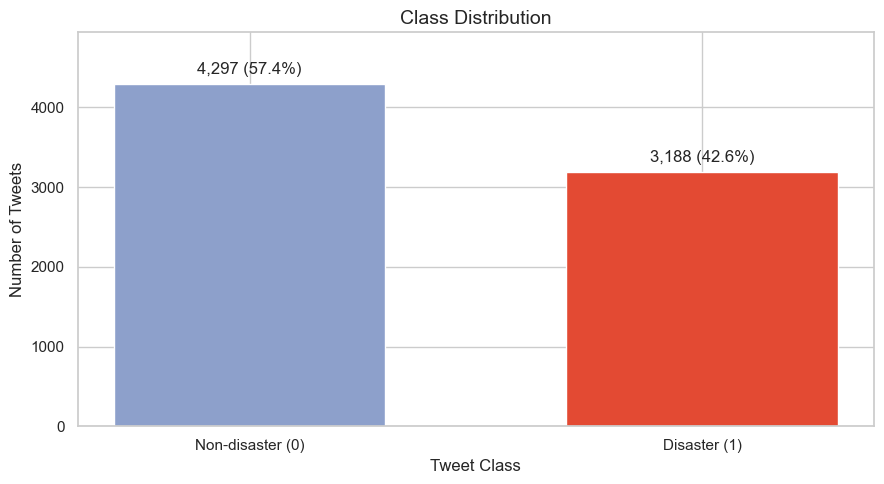

Chart saved at: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures\01_class_distribution.png


In [18]:
# Class distribution

%matplotlib inline


# Set output directory
FIG = r"D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures"
os.makedirs(FIG, exist_ok=True)

# Check dataset
if "df" not in globals():
    raise NameError("DataFrame 'df' is not loaded. Load your dataset first.")

if "target" not in df.columns:
    raise KeyError("Column 'target' not found in the dataset.")

# Calculate class distribution
counts = df["target"].value_counts().reindex([0, 1], fill_value=0)
labels = ["Non-disaster (0)", "Disaster (1)"]

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    counts.values,
    color=["#8da0cb", "#e34a33"],
    width=0.6
)

# Add counts and percentages
for bar, value in zip(bars, counts.values):
    percentage = value / len(df) * 100 if len(df) else 0

    ax.annotate(
        f"{value:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title("Class Distribution", fontsize=14)
ax.set_xlabel("Tweet Class")
ax.set_ylabel("Number of Tweets")
ax.set_ylim(0, max(counts.max() * 1.15, 1))

plt.tight_layout()

# Save and display
output_path = os.path.join(FIG, "01_class_distribution.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved at:", output_path)


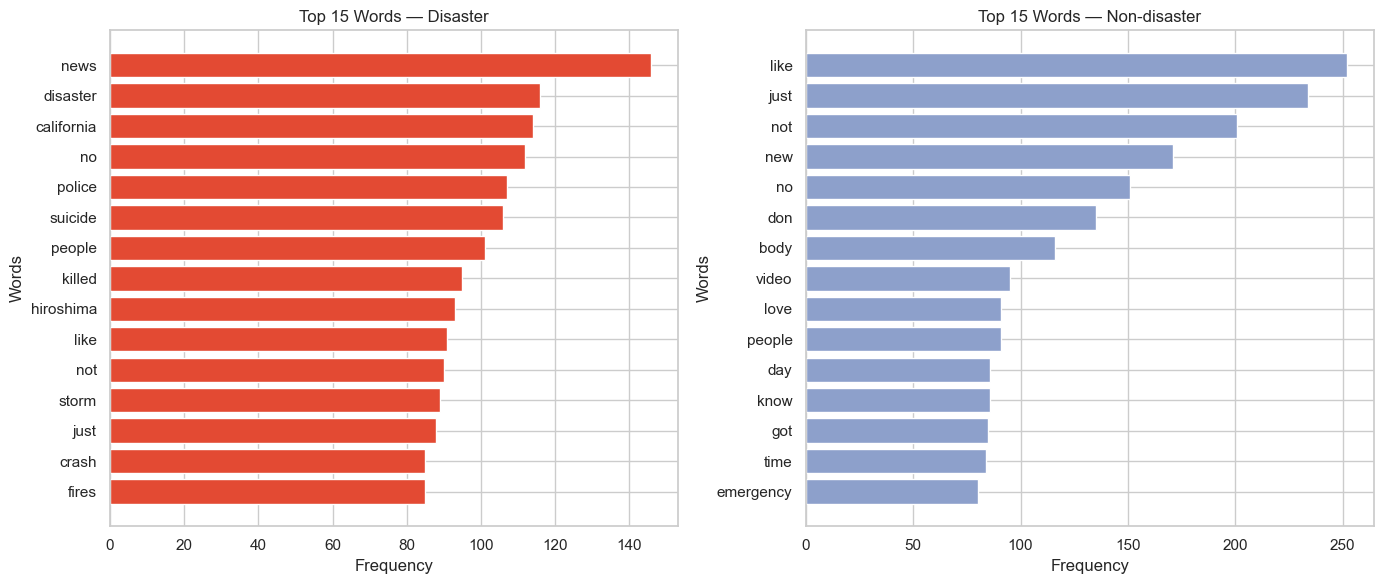

Chart saved successfully: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures\02_top_words.png


In [19]:
# Most frequent words per class (after cleaning)
from features import tokenize
from collections import Counter

# Ensure output directory exists
os.makedirs(FIG, exist_ok=True)

# Function to find the most frequent words
def top_words(texts, n=15):
    counter = Counter()

    for text in texts.dropna():
        words = tokenize(str(text))
        counter.update(words)

    return counter.most_common(n)


# Check required columns
if "text" not in df.columns or "target" not in df.columns:
    raise KeyError("Dataset must contain 'text' and 'target' columns.")

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

classes = [
    (1, "#e34a33", "Disaster"),
    (0, "#8da0cb", "Non-disaster")
]

for ax, (lab, color, title) in zip(axes, classes):

    texts = df.loc[df["target"] == lab, "text"]
    tw = top_words(texts, n=15)

    if tw:
        words = [word for word, count in tw][::-1]
        counts = [count for word, count in tw][::-1]

        ax.barh(words, counts, color=color)
        ax.set_xlabel("Frequency")
        ax.set_ylabel("Words")
        ax.set_title(f"Top 15 Words — {title}")
    else:
        ax.set_title(f"No words available — {title}")

plt.tight_layout()

# Save the figure
output_path = os.path.join(FIG, "02_top_words.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")

# Display the plot in Jupyter
plt.show()

print(f"Chart saved successfully: {output_path}")


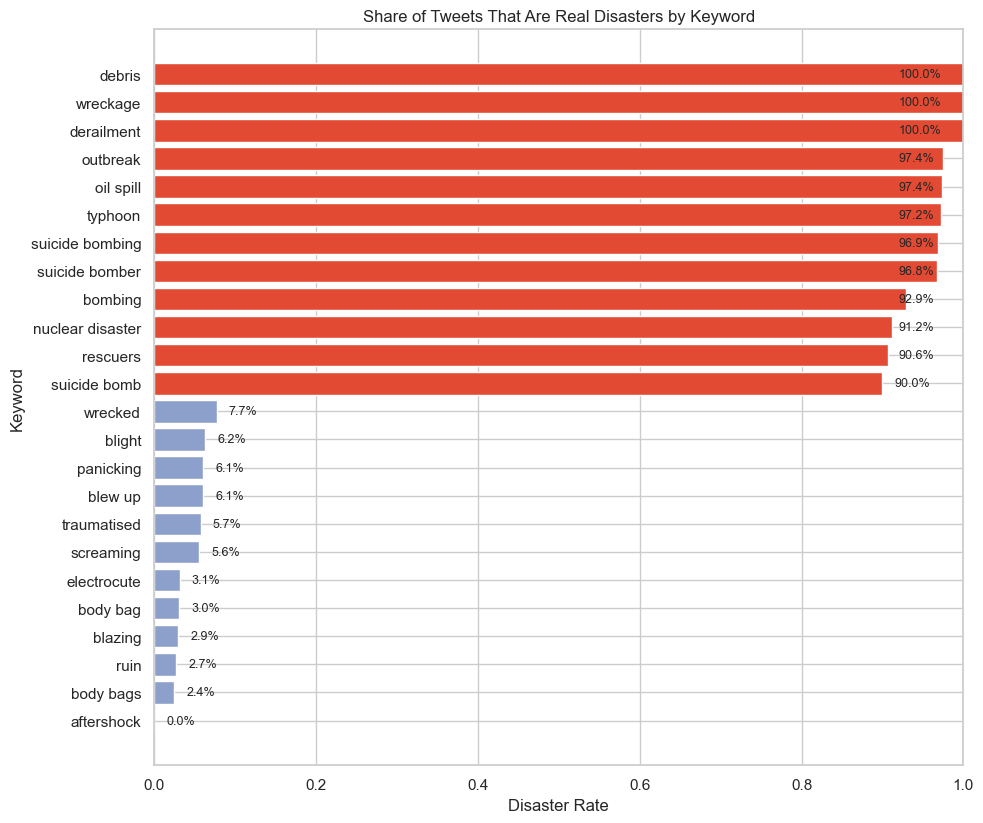

Chart saved successfully: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures\03_keyword_disaster_rate.png


In [20]:
# Which keywords are most disaster-related? (keyword column)
# Ensure output directory exists
os.makedirs(FIG, exist_ok=True)

# Check required columns
required_cols = {"keyword", "target"}
missing_cols = required_cols - set(df.columns)

if missing_cols:
    raise KeyError(f"Missing columns in df: {missing_cols}")

# Calculate disaster rate by keyword
kw = (
    df.dropna(subset=["keyword", "target"])
      .groupby("keyword")["target"]
      .agg(["mean", "count"])
)

# Keep keywords appearing at least 20 times
kw = kw[kw["count"] >= 20].sort_values("mean")

if kw.empty:
    print("No keywords have at least 20 records.")
else:
    # Select 12 lowest and 12 highest disaster rates
    sel = pd.concat([kw.head(12), kw.tail(12)])
    sel = sel[~sel.index.duplicated(keep="first")]

    # Clean keyword labels
    labels = (
        sel.index.astype(str)
        .str.replace("%20", " ", regex=False)
        .str.replace("_", " ", regex=False)
    )

    # Assign colors according to disaster rate
    colors = [
        "#8da0cb" if rate < 0.5 else "#e34a33"
        for rate in sel["mean"]
    ]

    # Plot
    fig, ax = plt.subplots(figsize=(10, max(6, len(sel) * 0.35)))

    bars = ax.barh(
        labels,
        sel["mean"],
        color=colors
    )

    ax.set_title("Share of Tweets That Are Real Disasters by Keyword")
    ax.set_xlabel("Disaster Rate")
    ax.set_ylabel("Keyword")
    ax.set_xlim(0, 1)

    # Add percentage labels
    for bar, rate in zip(bars, sel["mean"]):
        ax.text(
            min(rate + 0.015, 0.92),
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.1%}",
            va="center",
            fontsize=9
        )

    plt.tight_layout()

    # Save chart
    output_path = os.path.join(FIG, "03_keyword_disaster_rate.png")
    plt.savefig(output_path, dpi=150, bbox_inches="tight")

    # Display chart
    plt.show()

    print(f"Chart saved successfully: {output_path}")

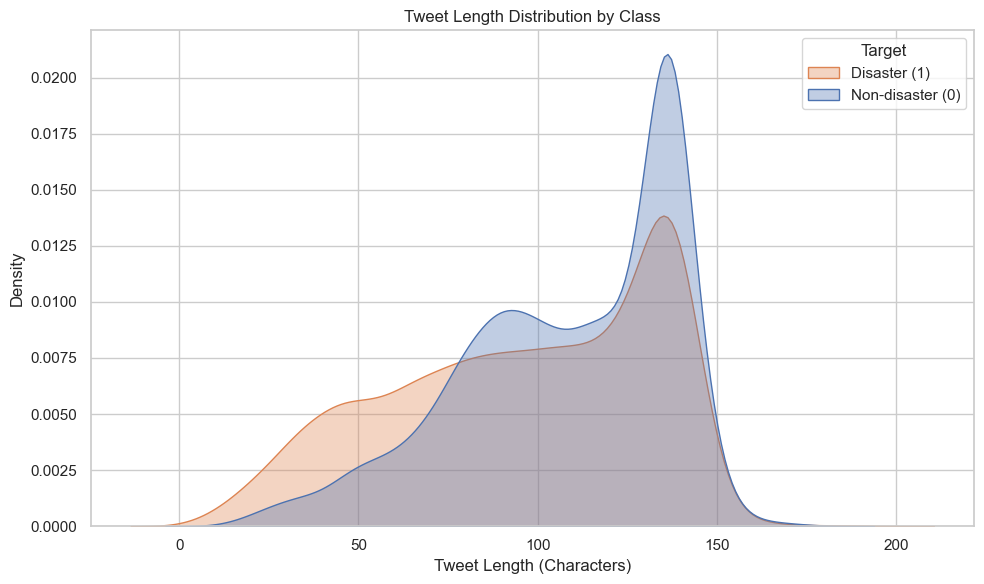

Chart saved successfully: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\figures\04_length_by_class.png


In [21]:
# Tweet length by class
# Create output directory
os.makedirs(FIG, exist_ok=True)

# Check required columns
required_cols = {"text", "target"}
missing_cols = required_cols - set(df.columns)

if missing_cols:
    raise KeyError(f"Missing columns in df: {missing_cols}")

# Calculate tweet length in characters
df["n_chars"] = df["text"].fillna("").astype(str).str.len()

# Prepare valid data for plotting
plot_df = df.dropna(subset=["target"]).copy()
plot_df["target"] = plot_df["target"].astype(str)

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.kdeplot(
    data=plot_df,
    x="n_chars",
    hue="target",
    fill=True,
    common_norm=False,
    alpha=0.35,
    warn_singular=False,
    ax=ax
)

ax.set_title("Tweet Length Distribution by Class")
ax.set_xlabel("Tweet Length (Characters)")
ax.set_ylabel("Density")
ax.legend(
    title="Target",
    labels=["Disaster (1)", "Non-disaster (0)"]
)

plt.tight_layout()

# Save chart
output_path = os.path.join(FIG, "04_length_by_class.png")
plt.savefig(output_path, dpi=150, bbox_inches="tight")

# Display chart
plt.show()

print(f"Chart saved successfully: {output_path}")

In [22]:
# Data quality: duplicate texts (some carry conflicting labels) -> remove to avoid train/test leakage
dup_texts = df["text"].duplicated(keep=False).sum()
conflict = (df.groupby("text")["target"].nunique() > 1).sum()
print(f"Rows sharing a duplicate text: {dup_texts}; texts with conflicting labels: {conflict}")
# drop conflicting-label texts entirely, keep first of the rest
bad = df.groupby("text")["target"].nunique()
bad = set(bad[bad > 1].index)
df = df[~df["text"].isin(bad)].drop_duplicates(subset="text").reset_index(drop=True)
print("Rows after de-duplication:", len(df))

Rows sharing a duplicate text: 0; texts with conflicting labels: 0
Rows after de-duplication: 7485


In [23]:
# Cleaning demo
for t in df["text"].sample(3, random_state=1):
    print("RAW  :", t); print("CLEAN:", clean_text(t)); print("TOKEN:", tokenize(t)); print()

RAW  : Fears over missing migrants in Med: Rescuers search for survivors after a boat carrying as many as 600 migrant... http://t.co/gx9sKUAu9J
CLEAN: fears over missing migrants in med rescuers search for survivors after a boat carrying as many as migrant
TOKEN: ['fears', 'missing', 'migrants', 'med', 'rescuers', 'search', 'survivors', 'boat', 'carrying', 'migrant']

RAW  : @JackMulholland1 I think also became THE MARQUIS! Then Carlos &amp; Charlie's and finally Dublin's. Sadly demolished.
CLEAN: i think also became the marquis then carlos charlie s and finally dublin s sadly demolished
TOKEN: ['think', 'marquis', 'carlos', 'charlie', 'finally', 'dublin', 'sadly', 'demolished']

RAW  : How do you call yourself a base conservative when u think it's okay 2 duck military service &amp; contribute thousands 2 #HillaryClinton 2012?
CLEAN: how do you call yourself a base conservative when u think it s okay duck military service contribute thousands hillaryclinton
TOKEN: ['base', 'conservativ

In [24]:
# Labels are already numeric (0/1). Stratified train/test split.
X = df[["text", "keyword"]]; y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(5988, 2) (1497, 2) 0.426 0.426


## Part 2 — Feature engineering & model selection
Features = TF-IDF (1–2 grams on cleaned text + keyword token) **+** hand-crafted meta features
(length, #hashtags, #mentions, URL flag, caps ratio, …).

In [10]:
def make_features(ngram=(1, 2), min_df=2):
    return FeatureUnion([
        ("tfidf", Pipeline([("prep", TextPrep()),
                            ("vec", TfidfVectorizer(ngram_range=ngram, min_df=min_df, sublinear_tf=True))])),
        ("meta", Pipeline([("m", MetaFeatures()), ("s", MinMaxScaler())])),
    ])

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=2, class_weight="balanced"),
    "Multinomial NB": MultinomialNB(alpha=0.5),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, class_weight="balanced", random_state=SEED),
    "MLP (neural net)": MLPClassifier(hidden_layer_sizes=(128,), early_stopping=True, max_iter=60, random_state=SEED),
}

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("features", make_features()), ("clf", clf)])
    cv = cross_validate(pipe, X_train, y_train, cv=skf, n_jobs=-1,
                        scoring=["accuracy", "precision", "recall", "f1"])
    rows.append({"model": name, **{m: cv[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]},
                 "f1_std": cv["test_f1"].std()})
    print(f"{name:22s} F1={rows[-1]['f1']:.4f} ± {rows[-1]['f1_std']:.4f}")
cv_df = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
cv_df.round(4).to_csv(os.path.join(ROOT, "reports", "cv_results.csv"), index=False)
cv_df.round(4)

Logistic Regression    F1=0.7595 ± 0.0143
Multinomial NB         F1=0.7489 ± 0.0107
Linear SVM             F1=0.7584 ± 0.0133
Random Forest          F1=0.6990 ± 0.0200
MLP (neural net)       F1=0.7543 ± 0.0173


,model,accuracy,precision,recall,f1,f1_std
0,Logistic Regression,0.7936,0.7544,0.7651,0.7595,0.0143
1,Linear SVM,0.8021,0.7904,0.7294,0.7584,0.0133
2,MLP (neural net),0.8056,0.8164,0.7027,0.7543,0.0173
3,Multinomial NB,0.8083,0.8464,0.6718,0.7489,0.0107
4,Random Forest,0.7770,0.8217,0.6086,0.6990,0.0200


In [11]:
# Hyper-parameter tuning (grid search) on the two strongest model families
tune = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"clf__C": [0.5, 1, 2, 5, 10]}),
    "Linear SVM": (CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3),
                   {"clf__estimator__C": [0.1, 0.3, 0.5, 1]}),
}
searches = {}
for name, (clf, grid) in tune.items():
    grid = {**grid, "features__tfidf__vec__ngram_range": [(1, 1), (1, 2)], "features__tfidf__vec__min_df": [1, 2]}
    gs = GridSearchCV(Pipeline([("features", make_features()), ("clf", clf)]), grid,
                      cv=skf, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train); searches[name] = gs
    print(f"{name}: best CV F1={gs.best_score_:.4f}  params={gs.best_params_}")

Logistic Regression: best CV F1=0.7632  params={'clf__C': 10, 'features__tfidf__vec__min_df': 1, 'features__tfidf__vec__ngram_range': (1, 2)}
Linear SVM: best CV F1=0.7663  params={'clf__estimator__C': 1, 'features__tfidf__vec__min_df': 1, 'features__tfidf__vec__ngram_range': (1, 2)}


## Part 3 — Evaluation & validation on the held-out test set

In [12]:
def evaluate(model, name):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "roc_auc": auc(*roc_curve(y_test, proba)[:2]), "avg_precision": average_precision_score(y_test, proba)}, proba, pred

results, probas, preds = [], {}, {}
for name, gs in searches.items():
    r, p, pr = evaluate(gs.best_estimator_, f"{name} (tuned)"); results.append(r); probas[r["model"]] = p; preds[r["model"]] = pr
# untuned baselines for comparison
for name in ["Multinomial NB", "Random Forest", "MLP (neural net)"]:
    m = Pipeline([("features", make_features()), ("clf", candidates[name])]).fit(X_train, y_train)
    r, p, pr = evaluate(m, name); results.append(r); probas[name] = p; preds[name] = pr

res = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
res.round(4).to_csv(os.path.join(ROOT, "reports", "test_results.csv"), index=False)
print(res.round(4).to_string())
best_name = res.loc[0, "model"]; print("\nBest model:", best_name)

                         model  accuracy  precision  recall      f1  roc_auc  avg_precision
0           Linear SVM (tuned)    0.7829     0.7630  0.7116  0.7364   0.8435         0.8354
1  Logistic Regression (tuned)    0.7776     0.7440  0.7288  0.7363   0.8430         0.8381
2             MLP (neural net)    0.7896     0.8372  0.6285  0.7180   0.8422         0.8379
3               Multinomial NB    0.7889     0.8426  0.6207  0.7148   0.8379         0.8338
4                Random Forest    0.7582     0.7974  0.5799  0.6715   0.8164         0.8056

Best model: Linear SVM (tuned)


In [26]:
# Visualisations: model comparison, confusion matrix, ROC, PR
res_m = res.melt(id_vars="model", value_vars=["accuracy", "precision", "recall", "f1"])
plt.figure(figsize=(10, 5)); sns.barplot(data=res_m, x="model", y="value", hue="variable")
plt.xticks(rotation=20, ha="right"); plt.ylim(0.6, 0.9); plt.title("Test-set metrics by model")
plt.tight_layout(); plt.savefig(f"{FIG}/05_model_comparison.png", dpi=130); plt.close()

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds[best_name]), display_labels=["Non-disaster", "Disaster"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix — {best_name}"); plt.tight_layout(); plt.savefig(f"{FIG}/06_confusion_matrix.png", dpi=130); plt.close()

plt.figure(figsize=(6, 5))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p); plt.plot(fpr, tpr, label=f"{n} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{FIG}/07_roc_curves.png", dpi=130); plt.close()

plt.figure(figsize=(6, 5))
for n, p in probas.items():
    pr_, rc_, _ = precision_recall_curve(y_test, p); plt.plot(rc_, pr_, label=f"{n} (AP {average_precision_score(y_test, p):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–recall curves"); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/08_pr_curves.png", dpi=130); plt.close()

print(classification_report(y_test, preds[best_name], target_names=["Non-disaster", "Disaster"]))

              precision    recall  f1-score   support

Non-disaster       0.80      0.84      0.82       859
    Disaster       0.76      0.71      0.74       638

    accuracy                           0.78      1497
   macro avg       0.78      0.77      0.78      1497
weighted avg       0.78      0.78      0.78      1497



In [14]:
# Over/under-fitting check: train vs CV vs test F1 for the best model
best_key = best_name.replace(" (tuned)", "")
final = searches[best_key].best_estimator_ if best_key in searches else None
train_f1 = f1_score(y_train, final.predict(X_train))
test_f1 = f1_score(y_test, final.predict(X_test))
cv_f1 = searches[best_key].best_score_
print(f"Train F1={train_f1:.3f} | CV F1={cv_f1:.3f} | Test F1={test_f1:.3f} | gap(train-test)={train_f1 - test_f1:.3f}")

Train F1=0.980 | CV F1=0.766 | Test F1=0.736 | gap(train-test)=0.243


In [15]:
# Error analysis: show confident mistakes
err = X_test.copy(); err["true"] = y_test.values; err["p_disaster"] = final.predict_proba(X_test)[:, 1]
err["pred"] = (err["p_disaster"] >= 0.5).astype(int)
errs = err[err.true != err.pred].assign(conf=lambda d: (d.p_disaster - 0.5).abs()).sort_values("conf", ascending=False)
errs.head(15)[["text", "true", "p_disaster"]].to_csv(os.path.join(ROOT, "reports", "top_errors.csv"), index=False)
print(errs.head(8)[["text", "true", "p_disaster"]].to_string())

                                                                                                                                         text  true  p_disaster
5313                                                                          all that panicking made me tired ;__; i want to sleep in my bed     1    0.013058
6215                                                                                 @Stretcher @witter @Rexyy @Towel show me a picture of it     1    0.015715
7449                                                                                        @Kirafrog @mount_wario Did you get wrecked again?     1    0.019354
1396         _x0089_ÛÏThe road to power is paved with hypocrisy and casualties._x0089_Û_x009d_ #FrancisUnderwood #HoC https://t.co/zqO6NUvYTu     0    0.972511
3372                                                                                        @allen_enbot If you mess up it's gonna explode...     1    0.029150
918   White family (supposedly represent

In [16]:
# Most influential terms (only meaningful for the linear model)
if best_key == "Logistic Regression":
    vec = final.named_steps["features"].transformer_list[0][1].named_steps["vec"]
    coefs = final.named_steps["clf"].coef_[0][: len(vec.get_feature_names_out())]
    names = np.array(vec.get_feature_names_out()); order = np.argsort(coefs)
    fig, ax = plt.subplots(figsize=(8, 6))
    idx = np.r_[order[:15], order[-15:]]
    ax.barh(names[idx], coefs[idx], color=["#8da0cb"] * 15 + ["#e34a33"] * 15)
    ax.set_title("Top terms: disaster (right) vs non-disaster (left)")
    plt.tight_layout(); plt.savefig(f"{FIG}/09_top_coefficients.png", dpi=130); plt.close()

## Part 4 — Serialize the final model
The entire pipeline (cleaning + features + classifier) is refit on **all** data and pickled,
so the Flask app only needs `predict_proba(DataFrame(text, keyword))`.

In [25]:
from sklearn.base import clone
final_full = clone(searches[best_key].best_estimator_).fit(X, y)
joblib.dump(final_full, os.path.join(ROOT, "models", "disaster_tweet_model.pkl"))
json.dump({"best_model": best_name, "test_metrics": {k: round(float(v), 4) for k, v in res.iloc[0].items() if k != "model"},
           "best_params": {k: str(v) for k, v in searches[best_key].best_params_.items()},
           "n_train": int(len(X_train)), "n_test": int(len(X_test))},
          open(os.path.join(ROOT, "models", "metadata.json"), "w"), indent=2)
print("Saved model + metadata.")

Saved model + metadata.
